# Лабораторная работа №2 — Классификация
**Датасет:** Titanic Dataset
**Цель:** предсказать выживание пассажира (`Survived`) и сравнить baseline, дерево решений, случайный лес, градиентный бустинг, SVM и KNN по метрикам классификации.

## 1. Импорт библиотек и настройки
Используем F1 для класса 1 как основную метрику. Все случайные процессы фиксированы значением `RANDOM_STATE`.

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Загрузка датасета
Положите Kaggle-файл `train.csv` рядом с ноутбуком либо в каталог `classification/`. Если локального файла нет, будет использована открытая копия Titanic из репозитория seaborn; в ней также есть `Survived` и основные признаки Titanic.

In [2]:
def load_titanic():
    candidates = [Path('train.csv'), Path('classification/train.csv')]
    for path in candidates:
        if path.exists():
            return pd.read_csv(path), f'локальный файл {path}'
    url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv'
    with urllib.request.urlopen(url, timeout=30) as response:
        return pd.read_csv(response), url

df, data_source = load_titanic()
print('Источник:', data_source)
print('Размер:', df.shape)
display(df.head())

Источник: https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv
Размер: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Первичный анализ данных
`PassengerId` — идентификатор, он не описывает свойства пассажира и может провоцировать запоминание объектов. Исключим его из признаков. В публичной копии seaborn есть `alive`, которое напрямую дублирует целевое значение, поэтому его тоже исключим. `class` дублирует `pclass`; оставим только `pclass`. Остальные признаки оценим по пропускам и распределениям.

In [3]:
print('Типы столбцов:')
display(df.dtypes.to_frame('dtype'))
print('Пропуски:')
display(df.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Полные дубликаты:', df.duplicated().sum())
print('Распределение Survived:')
display(df['survived'].value_counts(dropna=False).sort_index().to_frame('count'))
print('Доля классов:')
display(df['survived'].value_counts(normalize=True).sort_index().to_frame('share'))

Типы столбцов:


,dtype
survived,int64
pclass,int64
sex,str
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,str
class,str
who,str


Пропуски:


,missing
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


Полные дубликаты: 107
Распределение Survived:


,count
survived,
0,549
1,342


Доля классов:


,share
survived,
0,0.616162
1,0.383838


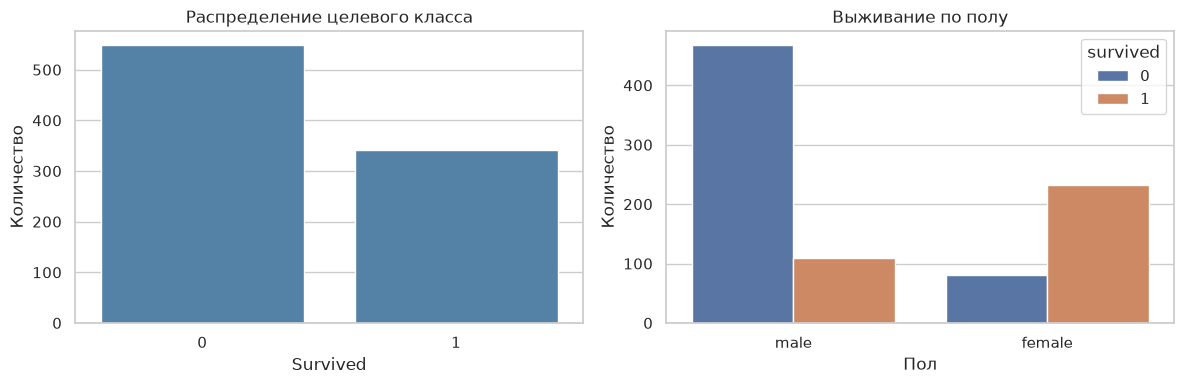

Вывод: классы выживших и погибших представлены не поровну, поэтому Accuracy в одиночку может скрывать качество обнаружения выживших. F1 объединяет Precision и Recall для положительного класса.
Возраст, тариф и порт посадки имеют пропуски. Импутация будет рассчитана только на обучающей части внутри Pipeline.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='survived', ax=axes[0], color='steelblue')
axes[0].set(title='Распределение целевого класса', xlabel='Survived', ylabel='Количество')
sns.countplot(data=df, x='sex', hue='survived', ax=axes[1])
axes[1].set(title='Выживание по полу', xlabel='Пол', ylabel='Количество')
plt.tight_layout(); plt.show()
print('Вывод: классы выживших и погибших представлены не поровну, поэтому Accuracy в одиночку может скрывать качество обнаружения выживших. F1 объединяет Precision и Recall для положительного класса.')
print('Возраст, тариф и порт посадки имеют пропуски. Импутация будет рассчитана только на обучающей части внутри Pipeline.')

## 4. Формирование выборок и обработка признаков
Оставляем содержательные сведения о пассажире: класс, пол, возраст, число родственников, тариф, порт посадки и палубу (если поле присутствует). Не используем идентификатор, `alive` и производные дубликаты класса. Разбиваем данные со стратификацией, чтобы доли классов были близки в train и test.

Для категориальных признаков используем наиболее частую категорию и one-hot encoding; для числовых — медиану. SVM и KNN особенно чувствительны к масштабу: без стандартизации числовой тариф мог бы доминировать в расстоянии. Поэтому для них добавим StandardScaler. Для деревьев масштабирование не требуется: разбиения основаны на порогах отдельных признаков.

In [5]:
TARGET = 'survived'
excluded = {'PassengerId', 'passenger_id', 'alive', 'class', 'who', 'adult_male', 'embark_town'}
feature_columns = [c for c in df.columns if c.lower() not in {x.lower() for x in excluded} and c != TARGET]
# deck сильно разрежен, но потенциально полезен; оставляем его и импутируем модой.
X = df[feature_columns].copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('Используемые признаки:', feature_columns)
print(f'Train: {X_train.shape[0]} строк, доля выживших {y_train.mean():.3f}')
print(f'Test:  {X_test.shape[0]} строк, доля выживших {y_test.mean():.3f}')

Используемые признаки: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'deck', 'alone']
Train: 712 строк, доля выживших 0.383
Test:  179 строк, доля выживших 0.385


In [6]:
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

def make_preprocessor(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    numeric = Pipeline(numeric_steps)
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('num', numeric, numeric_features),
        ('cat', categorical, categorical_features)
    ], remainder='drop')

def make_pipeline_model(estimator, scale_numeric=False):
    return Pipeline([('preprocess', make_preprocessor(scale_numeric)), ('model', estimator)])

## 5. Метрики и Dummy baseline
DummyClassifier всегда предсказывает самый частый класс, выбранный по train. Все модели оцениваются по одной и той же тестовой выборке. Confusion matrix читается так: строки — истинный класс, столбцы — предсказанный. False Positive — модель предсказала выживание для погибшего; False Negative — не распознала выжившего.

In [7]:
def calculate_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
    }

models = {
    'Decision Tree': make_pipeline_model(DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'Random Forest': make_pipeline_model(RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
    'Gradient Boosting': make_pipeline_model(GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE)),
    'SVM (RBF)': make_pipeline_model(SVC(C=1.0, kernel='rbf'), scale_numeric=True),
    'KNN': make_pipeline_model(KNeighborsClassifier(n_neighbors=11, weights='distance'), scale_numeric=True),
}

baseline = make_pipeline_model(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_train, y_train)
predictions = {'Dummy baseline': baseline.predict(X_test)}
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    predictions[name] = model.predict(X_test)

results = pd.DataFrame({name: calculate_metrics(y_test, pred) for name, pred in predictions.items()}).T
display(results.sort_values('F1', ascending=False).round(4))

,Accuracy,Precision,Recall,F1
Random Forest,0.8212,0.7846,0.7391,0.7612
SVM (RBF),0.8212,0.8364,0.6667,0.7419
KNN,0.8045,0.7656,0.7101,0.7368
Decision Tree,0.8045,0.7833,0.6812,0.7287
Gradient Boosting,0.8101,0.8302,0.6377,0.7213
Dummy baseline,0.6145,0.0000,0.0000,0.0000


## 6. Матрицы ошибок и сравнение
Сравнение метрик показывает компромисс Precision/Recall. В этой задаче False Negative означает пропустить пассажира, который выжил; False Positive — ошибочно предсказать выживание погибшего. В зависимости от контекста ошибки имеют разную цену, поэтому вместе с F1 рассматриваем обе составляющие.

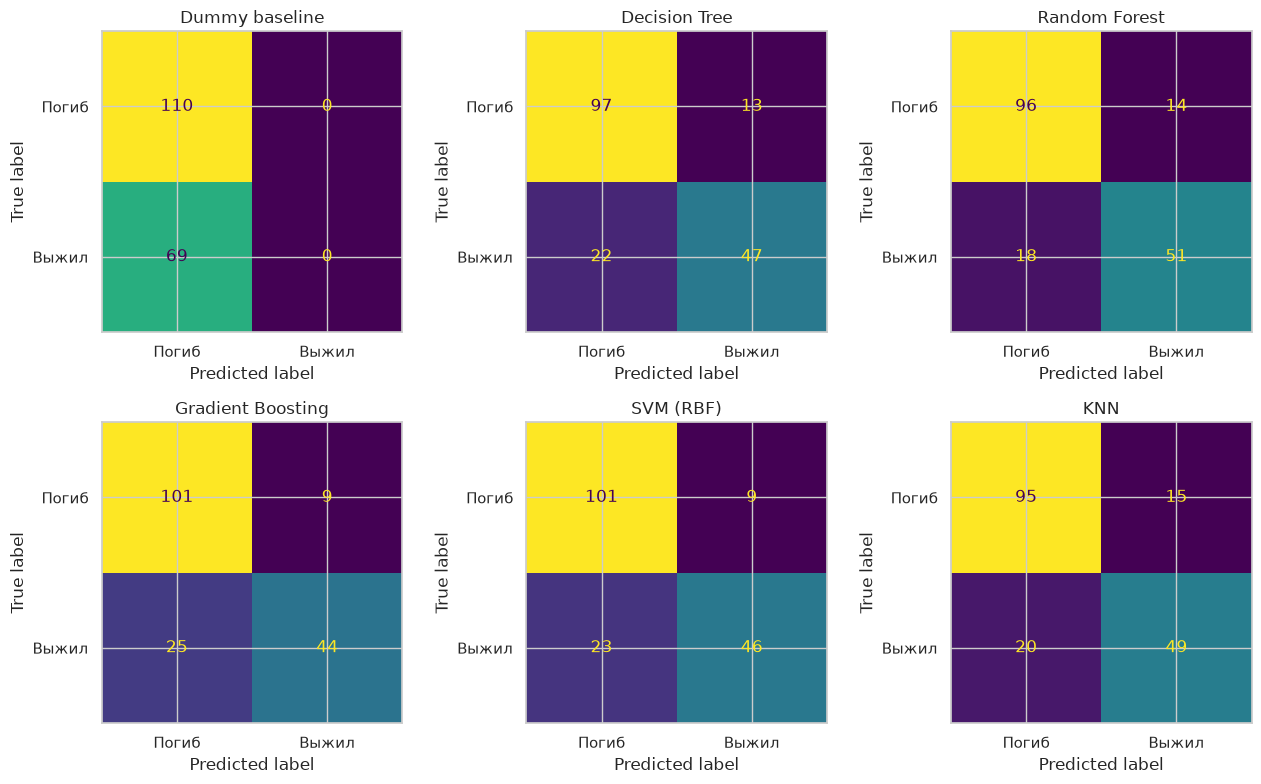

Baseline и модели на одном тестовом разбиении:


,Accuracy,Precision,Recall,F1
Dummy baseline,0.6145,0.0000,0.0000,0.0000
Decision Tree,0.8045,0.7833,0.6812,0.7287
Random Forest,0.8212,0.7846,0.7391,0.7612
Gradient Boosting,0.8101,0.8302,0.6377,0.7213
SVM (RBF),0.8212,0.8364,0.6667,0.7419
KNN,0.8045,0.7656,0.7101,0.7368


Порог F1 > 0.70:


,F1,above_threshold
Random Forest,0.761194,True
SVM (RBF),0.741935,True
KNN,0.736842,True
Decision Tree,0.728682,True
Gradient Boosting,0.721311,True
Dummy baseline,0.000000,False


Разница результатов может объясняться способностью моделей находить нелинейные зависимости и взаимодействия, регуляризацией, чувствительностью к масштабу и локальной плотностью объектов.


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Погиб', 'Выжил']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(name)
for ax in axes.flat[len(predictions):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

print('Baseline и модели на одном тестовом разбиении:')
display(results.round(4))
print('Порог F1 > 0.70:')
display(results.assign(above_threshold=results['F1'] > 0.70)[['F1', 'above_threshold']].sort_values('F1', ascending=False))
print('Разница результатов может объясняться способностью моделей находить нелинейные зависимости и взаимодействия, регуляризацией, чувствительностью к масштабу и локальной плотностью объектов.')

## 7. Выбор модели только на обучающей части
Для выбора модели под подробный разбор используем stratified 5-fold cross-validation на обучающих данных. Тестовые метрики не участвуют в выборе; тест остаётся финальной оценкой. Если запуск показывает F1 ниже 0.70, это следует честно отметить: нельзя подбирать решение по тесту.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1', n_jobs=1)
    cv_f1[name] = (scores.mean(), scores.std())
cv_table = pd.DataFrame(cv_f1, index=['CV F1 mean', 'CV F1 std']).T.sort_values('CV F1 mean', ascending=False)
display(cv_table.round(4))
best_name = cv_table.index[0]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print(f'Лучшая по среднему CV F1 на train: {best_name}')
print(f"Её финальный тестовый F1: {results.loc[best_name, 'F1']:.4f}")
print(f"Порог F1 > 0.70 выполнен: {results.loc[best_name, 'F1'] > 0.70}")

,CV F1 mean,CV F1 std
SVM (RBF),0.7571,0.0243
Random Forest,0.7439,0.0374
KNN,0.7390,0.0163
Gradient Boosting,0.7362,0.0427
Decision Tree,0.7210,0.0121


Лучшая по среднему CV F1 на train: SVM (RBF)
Её финальный тестовый F1: 0.7419
Порог F1 > 0.70 выполнен: True


## 8. Переобучение дерева и важность признаков
Сравним train и test для дерева решений. Существенно более высокие train-метрики указывают на переобучение. Feature importance доступна у дерева, Random Forest и Gradient Boosting. Это относительное использование признаков моделью, а не причинный эффект.

,Accuracy,Precision,Recall,F1
Train,0.8525,0.8471,0.7509,0.7961
Test,0.8045,0.7833,0.6812,0.7287


Если качество на train заметно выше, чем на test, дерево переобучается. Ограничение глубины и минимального размера листа снижает этот риск.


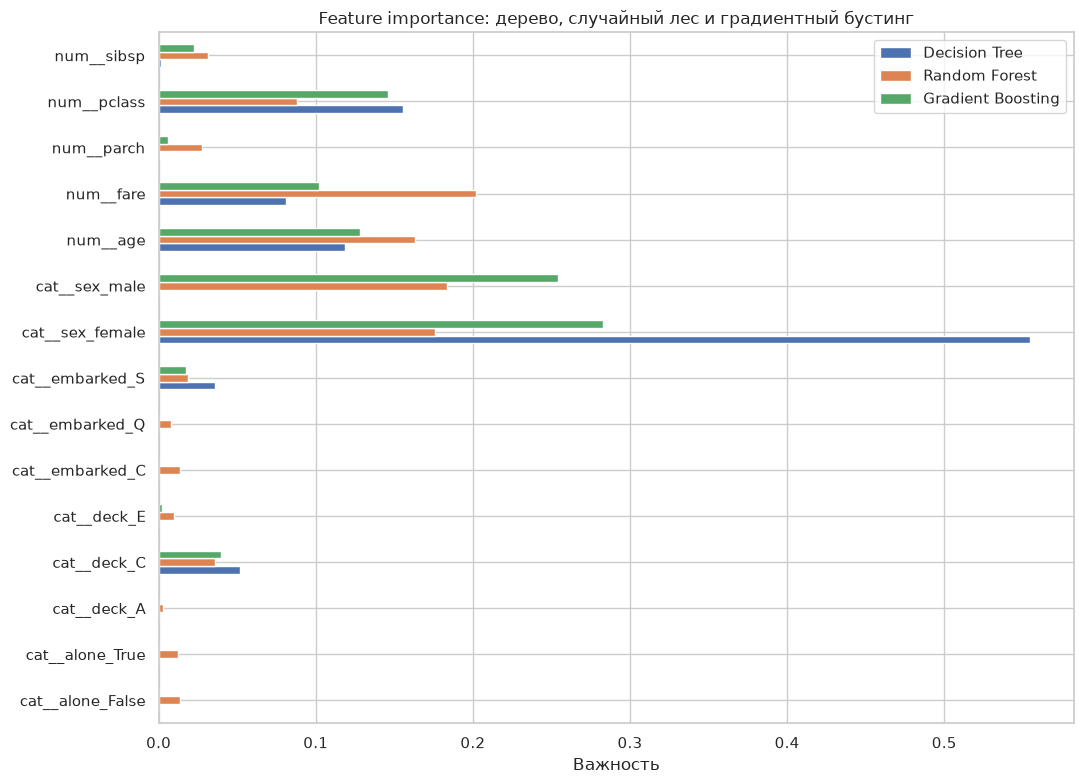

,Decision Tree,Random Forest,Gradient Boosting
num__fare,0.0811,0.2022,0.1019
cat__sex_male,0.0000,0.1837,0.2539
cat__sex_female,0.5548,0.1759,0.2831
num__age,0.1186,0.1631,0.1281
num__pclass,0.1555,0.0881,0.1460
cat__deck_C,0.0516,0.0357,0.0394
num__sibsp,0.0017,0.0314,0.0223
num__parch,0.0008,0.0274,0.0058
cat__embarked_S,0.0358,0.0190,0.0174
cat__alone_False,0.0000,0.0135,0.0000


Ожидаемо существенными могут быть пол, класс и тариф: это согласуется с различиями в распределении выживания по группам. Важный признак не обязательно является причиной выживания; важность зависит от данных, корреляций и устройства модели.


In [10]:
tree = fitted_models['Decision Tree']
tree_train_pred = tree.predict(X_train)
tree_test_pred = predictions['Decision Tree']
display(pd.DataFrame({
    'Train': calculate_metrics(y_train, tree_train_pred),
    'Test': calculate_metrics(y_test, tree_test_pred)
}).T.round(4))
print('Если качество на train заметно выше, чем на test, дерево переобучается. Ограничение глубины и минимального размера листа снижает этот риск.')

def get_importance(model):
    prep = model.named_steps['preprocess']
    names = prep.get_feature_names_out()
    values = model.named_steps['model'].feature_importances_
    return pd.Series(values, index=names)

importances = {name: get_importance(fitted_models[name]) for name in ['Decision Tree', 'Random Forest', 'Gradient Boosting']}
top_features = sorted(set().union(*(s.nlargest(12).index for s in importances.values())))
importance_table = pd.DataFrame({k: v.reindex(top_features, fill_value=0) for k, v in importances.items()})
importance_table.plot(kind='barh', figsize=(11, 8))
plt.title('Feature importance: дерево, случайный лес и градиентный бустинг')
plt.xlabel('Важность'); plt.tight_layout(); plt.show()
display(importance_table.sort_values('Random Forest', ascending=False).head(15).round(4))
print('Ожидаемо существенными могут быть пол, класс и тариф: это согласуется с различиями в распределении выживания по группам. Важный признак не обязательно является причиной выживания; важность зависит от данных, корреляций и устройства модели.')

## 9. Анализ ошибок выбранной модели
Посмотрим, в каких группах чаще возникают ошибки, и выведем несколько конкретных случаев. Сравнение выполняется на тестовых строках, не участвовавших в обучении.

In [11]:
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print('Ошибок False Negative больше.' if fn > fp else 'Ошибок False Positive больше.' if fp > fn else 'Число FP и FN одинаково.')

error_rows = X_test.copy()
error_rows['Survived_true'] = y_test
error_rows['Survived_pred'] = best_pred
error_rows['error_type'] = np.select(
    [(y_test.to_numpy() == 0) & (best_pred == 1), (y_test.to_numpy() == 1) & (best_pred == 0)],
    ['False Positive', 'False Negative'], default='Верно')
errors = error_rows[error_rows['error_type'] != 'Верно']
print('Ошибки по полу:')
display(errors.groupby(['sex', 'error_type'], dropna=False).size().unstack(fill_value=0))
if 'pclass' in errors:
    print('Ошибки по классу билета:')
    display(errors.groupby(['pclass', 'error_type'], dropna=False).size().unstack(fill_value=0))
print('Примеры ошибочно классифицированных пассажиров:')
display(errors.head(8))
print('Возможные причины: важные для выживания правила эвакуации не отражены полностью в таблице; группы перекрываются по возрасту, классу и тарифу; часть значений пропущена. Проверьте конкретные строки и confusion matrix, прежде чем делать вывод о преобладающем типе ошибки.')
print('Контроль утечки: идентификатор не входит в X, а `alive` (прямая копия ответа в копии seaborn) исключён. Все вычисляемые импутации и кодирование обучаются внутри Pipeline только на соответствующем train fold или полном train.')

TN=101, FP=9, FN=23, TP=46
Ошибок False Negative больше.
Ошибки по полу:


error_type,False Negative,False Positive
sex,,
female,4,8
male,19,1


Ошибки по классу билета:


error_type,False Negative,False Positive
pclass,,
1,9,2
2,2,1
3,12,6


Примеры ошибочно классифицированных пассажиров:


,pclass,sex,age,sibsp,parch,fare,embarked,deck,alone,Survived_true,Survived_pred,error_type
553,3,male,22.0,0,0,7.2250,C,NaN,True,1,0,False Negative
559,3,female,36.0,1,0,17.4000,S,NaN,False,1,0,False Negative
27,1,male,19.0,3,2,263.0000,S,C,False,0,1,False Positive
279,3,female,35.0,1,1,20.2500,S,NaN,False,1,0,False Negative
712,1,male,48.0,1,0,52.0000,S,C,False,1,0,False Negative
455,3,male,29.0,0,0,7.8958,C,NaN,True,1,0,False Negative
65,3,male,NaN,1,1,15.2458,C,NaN,False,1,0,False Negative
489,3,male,9.0,1,1,15.9000,S,NaN,False,1,0,False Negative


Возможные причины: важные для выживания правила эвакуации не отражены полностью в таблице; группы перекрываются по возрасту, классу и тарифу; часть значений пропущена. Проверьте конкретные строки и confusion matrix, прежде чем делать вывод о преобладающем типе ошибки.
Контроль утечки: идентификатор не входит в X, а `alive` (прямая копия ответа в копии seaborn) исключён. Все вычисляемые импутации и кодирование обучаются внутри Pipeline только на соответствующем train fold или полном train.


## 10. Итоговые выводы
1. Данные содержат числовые и категориальные признаки; возраст, тариф и некоторые категориальные поля могут иметь пропуски. Медианная/модальная импутация и one-hot encoding выполняются внутри конвейеров, поэтому тестовая информация не попадает в преобразования.
2. Основная метрика — F1 для выживших. Dummy baseline задаёт ориентир; итоговая таблица показывает Accuracy, Precision, Recall и F1 на общей тестовой выборке. Порог F1 > 0.70 оценивается по распечатанной таблице после запуска ноутбука.
3. Decision Tree, Random Forest и Gradient Boosting способны получить нелинейные зависимости; лес усредняет деревья, бустинг последовательно исправляет ошибки. SVM и KNN требуют масштабирования, поскольку используют геометрию признакового пространства.
4. Feature importance показывает, какие признаки модель использовала для предсказаний, но не доказывает причинность. Связь может отражать корреляцию, особенности выборки или взаимодействие признаков.
5. Матрица ошибок и разрез по группам позволяют увидеть, кого модель чаще ошибочно считает выжившим или погибшим. В Titanic результат нельзя трактовать как причинное объяснение исторического выживания.
6. Kaggle-файл и открытая копия seaborn могут различаться набором строк и столбцов. Для воспроизводимого сравнения в рамках курса используйте один и тот же файл данных и одинаковый `random_state`.